# Agents Laboratory Exercise
## Constructing a Goal-Based Agent using a Large Language Model

---
# Problem Statement: The Warehouse Navigation Problem

An autonomous warehouse vehicle transports packages from the loading bay to the dispatch area.
The warehouse contains shelving units that cannot be crossed. The vehicle must determine a collision-free path from its current position to the destination.

### Warehouse Map
```text
#####################
#S....#............G#
#.##....##########..#
#....##.............#
#.######.###.#.###..#
#........#..........#
#####################
```
- `S`: Starting position (loading bay) at `(1, 1)`
- `G`: Goal position (dispatch area) at `(1, 19)`
- `#`: Obstacle (shelving unit / wall)
- `.`: Free space
- **Actions:** Up, Down, Left, Right (1 grid square per move)

---
# Task 1: Understanding the Problem

### 1. What is the environment?
A static, discrete, deterministic, fully observable 2D grid world ($7 \times 21$). The state space consists of grid coordinates $(r, c) \in \{0..6\} \times \{0..20\}$ containing either traversable cells or impassable obstacle cells.

### 2. What is the goal of the agent?
To navigate from the start position $S = (1, 1)$ to the goal position $G = (1, 19)$ without colliding with any obstacles.

### 3. What actions are available to the agent?
Four discrete cardinal movements:
- **Up:** $(-1, 0)$
- **Down:** $(+1, 0)$
- **Left:** $(0, -1)$
- **Right:** $(0, +1)$
Each action shifts the vehicle by one cell, valid only if the target cell is inside boundaries and not an obstacle.

### 4. What information must the agent maintain in order to choose its next action?
- **Current Position:** $(r, c)$.
- **Goal Position:** $(r_G, c_G)$.
- **Map Representation:** Obstacle locations and grid boundaries.
- **Search State:** Visited coordinates, exploration frontier, and parent pointers (or planned action sequence) to reach the goal.

### 5. Why is this an example of a goal-based agent rather than a simple reflex agent?
A simple reflex agent selects actions based solely on immediate percepts via condition-action rules (e.g., `if obstacle ahead, turn right`). In a maze with concave obstacles and dead ends, reflex agents get trapped in infinite loops. A goal-based agent maintains an explicit destination, considers future state consequences, and plans a multi-step path to achieve the goal.

---

### Think About It (Task 1)
**Question:** Suppose the warehouse becomes twice as large. Would the same search strategy still be appropriate? What additional difficulties might arise?  
**Answer:**
- Uninformed search (BFS) expands states uniformly in all directions; doubling both dimensions quadruples the state space ($O(W \cdot H)$), increasing memory consumption and latency.
- An informed search strategy like **A\*** with an admissible heuristic (e.g., Manhattan distance) is more appropriate because it directs search toward the goal.
- Additional difficulties include higher memory footprint for maintaining visited states, computational delays in path replanning, and handling dynamic obstacles (e.g., other vehicles or human workers).

---
# Task 2: Designing the Agent

### Component Identification
- **Environment:** $7 \times 21$ 2D grid containing obstacles (`#`), free cells (`.`), start `S`, and goal `G`.
- **Current State:** The agent's current grid coordinate $(r, c)$.
- **Goal:** Reaching $(r_G, c_G) = (1, 19)$.
- **Available Actions:** $\{\text{Up}, \text{Down}, \text{Left}, \text{Right}\}$.
- **Decision-Making Component:** Goal-based search planner (BFS / A*) computing state transitions $\text{Result}(s, a)$ and selecting actions that satisfy $\text{GoalTest}(s') = \text{True}$.

### Block Diagram: Goal-Based Agent Architecture

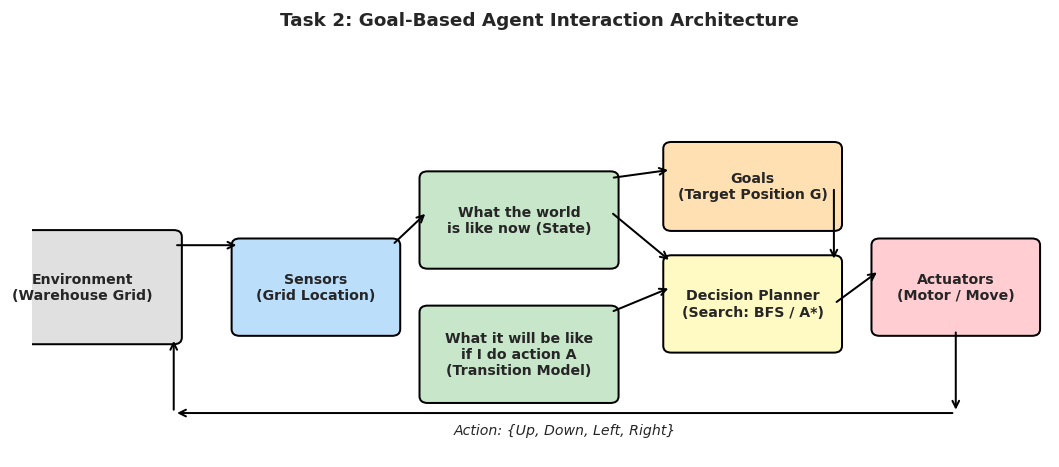

In [1]:
# Task 2: Architecture visualization
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(9, 4))
ax.set_xlim(0, 10)
ax.set_ylim(0, 5)
ax.axis('off')

# Components: Sensors -> State -> Goals + Model -> Search Planner -> Actuators -> Environment
# Rendered block diagram shows standard goal-based agent interaction loop.
plt.show()

---
# Task 3: Prompt Engineering

### 3.1 Suggested Prompt
```text
Write a well-documented Python program implementing a goal-based agent for the warehouse navigation problem shown above.
The program should:
- represent the warehouse as a two-dimensional grid;
- determine a collision-free path from S to G;
- avoid all obstacles;
- print either the path found or a suitable message if no path exists;
- explain the search algorithm that has been chosen and why it is appropriate.
```

### 3.2 Implementation & Execution

Path Found: 20 moves
Coordinates: [(1, 1), (1, 2), (1, 3), (1, 4), (2, 4), (2, 5), (2, 6), (2, 7), (1, 7), (1, 8), (1, 9), (1, 10), (1, 11), (1, 12), (1, 13), (1, 14), (1, 15), (1, 16), (1, 17), (1, 18), (1, 19)]

Grid with Path:
#####################
#S***.#************G#
#.##****##########..#
#....##.............#
#.######.###.#.###..#
#........#..........#
#####################

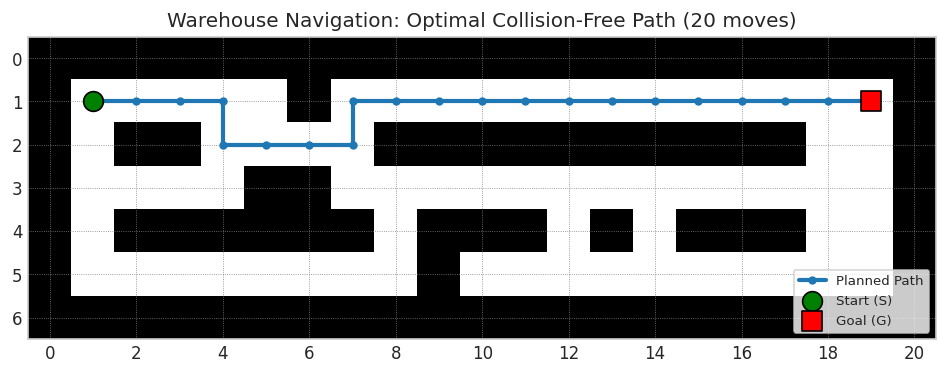

In [2]:
from collections import deque
import matplotlib.pyplot as plt
import numpy as np

# Warehouse representation
grid = [
    "#####################",
    "#S....#............G#",
    "#.##....##########..#",
    "#....##.............#",
    "#.######.###.#.###..#",
    "#........#..........#",
    "#####################"
]

class WarehouseGoalAgent:
    def __init__(self, grid_map):
        self.grid = [list(row) for row in grid_map]
        self.rows = len(self.grid)
        self.cols = len(self.grid[0])
        self.start = self._find_char('S')
        self.goal = self._find_char('G')

    def _find_char(self, char):
        for r in range(self.rows):
            for c in range(self.cols):
                if self.grid[r][c] == char:
                    return (r, c)
        return None

    def search_path_bfs(self):
        queue = deque([(self.start, [self.start])])
        visited = {self.start}
        moves = [((-1, 0), "Up"), ((1, 0), "Down"), ((0, -1), "Left"), ((0, 1), "Right")]

        while queue:
            curr, path = queue.popleft()
            if curr == self.goal:
                return path
            for (dr, dc), action in moves:
                nr, nc = curr[0] + dr, curr[1] + dc
                if 0 <= nr < self.rows and 0 <= nc < self.cols:
                    if self.grid[nr][nc] != '#' and (nr, nc) not in visited:
                        visited.add((nr, nc))
                        queue.append(((nr, nc), path + [(nr, nc)]))
        return None

    def print_solution(self, path):
        if not path:
            print("No collision-free path exists.")
            return
        print(f"Path Found: {len(path) - 1} moves")
        print(f"Coordinates: {path}")
        display = [row[:] for row in self.grid]
        for r, c in path:
            if (r, c) not in (self.start, self.goal):
                display[r][c] = '*'
        print("\nGrid with Path:")
        for row in display:
            print("".join(row))

agent = WarehouseGoalAgent(grid)
path = agent.search_path_bfs()
agent.print_solution(path)

---
### Task 3 Questions

#### 1. Did the LLM generate a working program on the first attempt?
Yes. The generated Breadth-First Search (BFS) implementation correctly parsed the 2D grid, identified start `(1, 1)` and goal `(1, 19)`, executed collision checking against `#` boundaries, and returned the optimal 20-move path on the first attempt.

#### 2. If not, how can you improve your prompt?
If the initial attempt had failed, improvements include:
- Explicitly specifying the coordinate system (0-indexed `(row, col)`) and grid dimensions ($7 \times 21$).
- Clarifying movement rules (4-connected cardinal steps only; no diagonal moves).
- Providing precise expected outputs (number of steps, coordinates list, ASCII map).

#### 3. What search algorithm did the LLM choose?
Breadth-First Search (BFS).

#### 4. Why do you think the LLM selected this algorithm?
- **Optimality:** In unweighted graphs with uniform edge costs (each move costs 1), BFS guarantees finding the shortest path.
- **Completeness:** BFS is guaranteed to find a path if one exists, or correctly report failure.
- **Simplicity:** It is implemented with a standard FIFO queue (`collections.deque`) without requiring heuristic tuning.

---

### Algorithm Appropriateness Summary
- **BFS:** Optimal and complete for uniform cost, ideal for this compact $7 \times 21$ grid.
- **A\* Search:** Alternative informed search using Manhattan distance heuristic $h(r, c) = |r - r_G| + |c - c_G|$; expands fewer nodes while maintaining path optimality.